# Day 6 – End-to-End ML Pipeline & Business Insights
## Uber Eats Operational & Customer Intelligence System

**Objective:** Bring the capstone's ML components together and translate analytical outputs into evidence-based business decisions.

### Capstone integration areas
1. Customer and restaurant segmentation
2. Customer review sentiment analysis
3. Delivery-time prediction
4. Hourly demand forecasting

### Workflow
**Raw Data → Cleaning → Feature Engineering → Modeling → Evaluation → Prediction → Business Insight**

This notebook integrates saved outputs from Days 2–5 where available, reads the original synthetic tables, builds a unified evidence table, and produces a business insights report. It is designed to tolerate optional outputs being absent and will clearly report what it could not find.

> **Important:** All source data is synthetic. The recommendations are examples for the capstone and are not claims about real Uber Eats operations. Run this notebook from the project's `notebooks/` folder.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data" / "synthetic"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
DOCS_DIR = PROJECT_ROOT / "docs"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Synthetic data directory:", DATA_DIR, "| exists:", DATA_DIR.exists())
print("Processed outputs:", PROCESSED_DIR)
print("Synthetic CSV files:", [p.name for p in DATA_DIR.glob("*.csv")])

Project root: /home/nineleaps/uber-eats-intelligence
Synthetic data directory: /home/nineleaps/uber-eats-intelligence/data/synthetic | exists: True
Processed outputs: /home/nineleaps/uber-eats-intelligence/data/processed
Synthetic CSV files: ['reviews.csv', 'customers.csv', 'restaurants.csv', 'orders.csv', 'deliveries.csv', 'drivers.csv', 'payments.csv']


## 2. Helper functions and load available data

In [2]:
def read_csv_if_exists(path):
    path = Path(path)
    if path.exists():
        try:
            df = pd.read_csv(path)
            print(f"Loaded {path.name}: {df.shape}")
            return df
        except Exception as exc:
            print(f"Could not read {path}: {exc}")
    else:
        print(f"Not found: {path}")
    return None

def norm_name(value):
    return "".join(ch.lower() for ch in str(value) if ch.isalnum())

def find_col(frame, candidates):
    if frame is None:
        return None
    lookup = {norm_name(c): c for c in frame.columns}
    for candidate in candidates:
        if norm_name(candidate) in lookup:
            return lookup[norm_name(candidate)]
    for candidate in candidates:
        key = norm_name(candidate)
        for normalized, original in lookup.items():
            if key and (key in normalized or normalized in key):
                return original
    return None

table_names = [
    "orders", "deliveries", "customers", "restaurants",
    "drivers", "payments", "reviews"
]
raw = {name: read_csv_if_exists(DATA_DIR / f"{name}.csv") for name in table_names}

processed_names = [
    "customer_cluster_profiles.csv",
    "restaurant_cluster_profiles.csv",
    "customer_features.csv",
    "restaurant_features.csv",
    "day3_nlp_evaluation_report.md",
    "day4_regression_model_comparison.csv",
    "day4_cross_validation_results.csv",
    "day4_permutation_importance.csv",
    "day4_test_predictions.csv",
    "day5_hourly_demand.csv",
    "day5_forecast_model_comparison.csv",
    "day5_next_24_hour_forecast.csv",
    "day5_adf_test_results.csv"
]
processed = {
    Path(name).stem: read_csv_if_exists(PROCESSED_DIR / name)
    for name in processed_names if not name.endswith(".md")
}

Loaded orders.csv: (10000, 14)
Loaded deliveries.csv: (9358, 6)
Loaded customers.csv: (1000, 5)
Loaded restaurants.csv: (100, 6)
Loaded drivers.csv: (200, 4)
Loaded payments.csv: (10000, 6)
Loaded reviews.csv: (7000, 7)
Loaded customer_cluster_profiles.csv: (2, 9)
Loaded restaurant_cluster_profiles.csv: (2, 8)
Loaded customer_features.csv: (1000, 11)
Loaded restaurant_features.csv: (100, 10)
Loaded day4_regression_model_comparison.csv: (5, 4)
Loaded day4_cross_validation_results.csv: (5, 7)
Loaded day4_permutation_importance.csv: (29, 3)
Loaded day4_test_predictions.csv: (1872, 3)
Loaded day5_hourly_demand.csv: (4319, 2)
Loaded day5_forecast_model_comparison.csv: (2, 4)
Loaded day5_next_24_hour_forecast.csv: (24, 2)
Loaded day5_adf_test_results.csv: (2, 8)


## 3. Data inventory and quality overview

,table,rows,columns,duplicate_rows,missing_cells
0,orders,10000,14,0,0
1,deliveries,9358,6,0,0
2,customers,1000,5,0,0
3,restaurants,100,6,0,0
4,drivers,200,4,0,0
5,payments,10000,6,0,0
6,reviews,7000,7,0,0


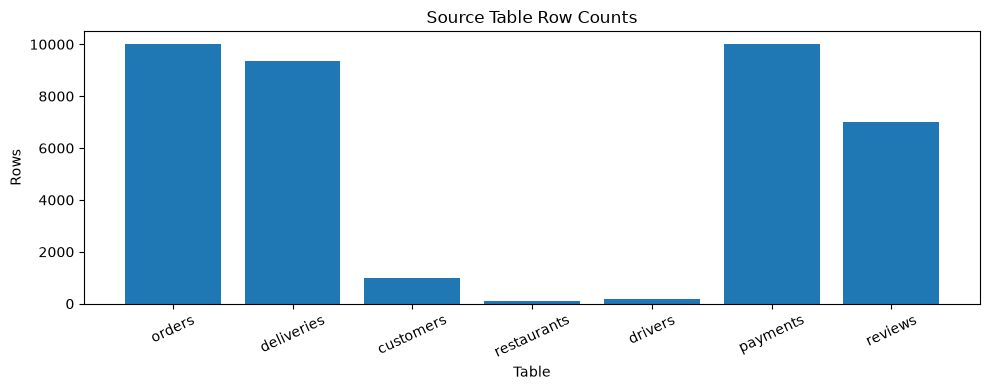

In [3]:
inventory_rows = []
for name, frame in raw.items():
    if frame is not None:
        inventory_rows.append({
            "table": name,
            "rows": len(frame),
            "columns": len(frame.columns),
            "duplicate_rows": int(frame.duplicated().sum()),
            "missing_cells": int(frame.isna().sum().sum())
        })
inventory = pd.DataFrame(inventory_rows)
display(inventory)
inventory.to_csv(PROCESSED_DIR / "day6_data_inventory.csv", index=False)

if not inventory.empty:
    plt.figure(figsize=(10, 4))
    plt.bar(inventory["table"], inventory["rows"])
    plt.title("Source Table Row Counts")
    plt.xlabel("Table")
    plt.ylabel("Rows")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "day6_source_table_row_counts.png", dpi=150)
    plt.show()

## 4. Integrate Day 2 – customer and restaurant segmentation

In [4]:
customer_profiles = processed.get("customer_cluster_profiles")
restaurant_profiles = processed.get("restaurant_cluster_profiles")
customer_features = processed.get("customer_features")
restaurant_features = processed.get("restaurant_features")

print("Customer cluster profiles:")
if customer_profiles is not None:
    display(customer_profiles)
else:
    print("Not available. Run the Day 2 notebook and save customer_cluster_profiles.csv.")

print("Restaurant cluster profiles:")
if restaurant_profiles is not None:
    display(restaurant_profiles)
else:
    print("Not available. Run the Day 2 notebook and save restaurant_cluster_profiles.csv.")

# Store a compact segmentation summary where possible.
segmentation_summary = []
for entity, frame in [("customer", customer_profiles), ("restaurant", restaurant_profiles)]:
    if frame is not None and not frame.empty:
        for _, row in frame.iterrows():
            segmentation_summary.append({
                "entity_type": entity,
                "cluster": row.iloc[0],
                "profile": " | ".join(
                    f"{col}={row[col]}" for col in frame.columns[1:]
                    if pd.notna(row[col])
                )
            })
segmentation_summary = pd.DataFrame(segmentation_summary)
display(segmentation_summary)
segmentation_summary.to_csv(PROCESSED_DIR / "day6_segmentation_summary.csv", index=False)

Customer cluster profiles:


,customer_cluster,customer_count,avg_orders,avg_order_value,avg_total_spending,avg_ordering_frequency,avg_rating_given,avg_weekend_orders,avg_late_night_orders
0,0,487,11.83,644.24,7574.04,0.07,3.00,3.49,3.75
1,1,513,7.01,621.17,4335.50,0.04,2.98,1.80,1.79


Restaurant cluster profiles:


,restaurant_cluster,restaurant_count,avg_orders,avg_revenue,avg_rating,avg_prep_time,avg_cancellation_rate,avg_delivery_time
0,0,50,94.72,59115.21,4.07,17.32,7.19,43.43
1,1,50,105.28,67364.01,4.16,31.30,5.74,57.49


,entity_type,cluster,profile
0,customer,0.0,customer_count=487.0 | avg_orders=11.83 | avg_...
1,customer,1.0,customer_count=513.0 | avg_orders=7.01 | avg_o...
2,restaurant,0.0,restaurant_count=50.0 | avg_orders=94.72 | avg...
3,restaurant,1.0,restaurant_count=50.0 | avg_orders=105.28 | av...


## 5. Integrate Day 3 – sentiment and customer complaint analysis

In [5]:
nlp_report_path = PROCESSED_DIR / "day3_nlp_evaluation_report.md"
clean_reviews_path = PROCESSED_DIR / "cleaned_reviews.csv"
clean_reviews = read_csv_if_exists(clean_reviews_path)

if nlp_report_path.exists():
    nlp_report_text = nlp_report_path.read_text(encoding="utf-8")
    print("Day 3 evaluation report found. Preview:")
    print(nlp_report_text[:3500])
else:
    nlp_report_text = ""
    print("Day 3 evaluation report not found. Run the Day 3 notebook's final cells.")

sentiment_summary = None
if clean_reviews is not None and not clean_reviews.empty:
    sentiment_col = find_col(clean_reviews, ["sentiment", "sentiment_label", "predicted_sentiment", "label"])
    rating_col = find_col(clean_reviews, ["rating", "review_rating", "stars"])
    if sentiment_col:
        sentiment_summary = clean_reviews[sentiment_col].astype(str).value_counts(dropna=False).rename_axis("sentiment").reset_index(name="review_count")
        display(sentiment_summary)
        sentiment_summary.to_csv(PROCESSED_DIR / "day6_sentiment_summary.csv", index=False)
    elif rating_col:
        print("No sentiment column detected; review rating distribution shown instead.")
        display(clean_reviews[rating_col].value_counts(dropna=False).sort_index().to_frame("review_count"))
    else:
        print("Loaded cleaned reviews, but could not detect sentiment or rating columns.")
else:
    print("Cleaned review dataset not found. Sentiment evidence will be marked unavailable.")

Loaded cleaned_reviews.csv: (7000, 13)
Day 3 evaluation report found. Preview:
# Day 3 — NLP Sentiment Analysis Report

- Reviews analyzed: 7000
- Review text column: `review_text`
- Rating column: `review_rating`
- Existing label column: `sentiment_label`
- NLTK lemmatization available: False
- VADER available: True

## Sentiment label distribution
sentiment_label
negative    2373
positive    2353
neutral     2274

## Naive Bayes evaluation
- Accuracy: 1.0000
- Macro precision: 1.0000
- Macro recall: 1.0000
- Macro F1-score: 1.0000

```text
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       593
     neutral       1.00      1.00      1.00       569
    positive       1.00      1.00      1.00       588

    accuracy                           1.00      1750
   macro avg       1.00      1.00      1.00      1750
weighted avg       1.00      1.00      1.00      1750

```

## VADER sentiment distribution
vader_sentiment
positive    3846
n

,sentiment,review_count
0,negative,2373
1,positive,2353
2,neutral,2274


## 6. Integrate Day 4 – delivery-time regression results

In [6]:
regression_comparison = processed.get("day4_regression_model_comparison")
cv_results = processed.get("day4_cross_validation_results")
permutation_importance = processed.get("day4_permutation_importance")
day4_predictions = processed.get("day4_test_predictions")

if regression_comparison is not None:
    display(regression_comparison)
else:
    print("Day 4 model comparison not found. Run Day 4 through its final report cell.")

if cv_results is not None:
    print("Cross-validation results:")
    display(cv_results)

if permutation_importance is not None:
    print("Top predictive features by permutation importance:")
    display(permutation_importance.head(10))

delivery_model_best = None
if regression_comparison is not None and not regression_comparison.empty:
    # Expected notebook schema: Model, MAE, RMSE, R2
    mae_col = find_col(regression_comparison, ["MAE"])
    model_col = find_col(regression_comparison, ["Model"])
    if mae_col and model_col:
        best_row = regression_comparison.loc[pd.to_numeric(regression_comparison[mae_col], errors="coerce").idxmin()]
        delivery_model_best = {
            "model": str(best_row[model_col]),
            "mae": float(best_row[mae_col]),
            "rmse": float(best_row[find_col(regression_comparison, ["RMSE"])]),
            "r2": float(best_row[find_col(regression_comparison, ["R2", "R_squared"])])
                if find_col(regression_comparison, ["R2", "R_squared"]) else np.nan
        }
        print("Best Day 4 model by MAE:", delivery_model_best)

,Model,MAE,RMSE,R2
0,Lasso Regression,4.024522,5.032505,0.909010
1,Ridge Regression,4.196614,5.243393,0.901224
2,Random Forest,4.380396,5.506455,0.891064
3,Linear Regression,4.523975,5.634144,0.885953
4,Dummy Baseline,13.204594,16.773838,-0.010862


Cross-validation results:


,Model,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_R2_std
0,Lasso Regression,4.011238,0.095496,5.032808,0.112161,0.907134,0.004621
1,Ridge Regression,4.169641,0.093913,5.237922,0.104475,0.899431,0.004370
2,Linear Regression,4.367001,0.113507,5.492603,0.113363,0.889406,0.005036
3,Random Forest,4.395750,0.074523,5.543769,0.119491,0.887325,0.005437
4,Dummy Baseline,13.046515,0.193913,16.599620,0.270431,-0.009244,0.005119


Top predictive features by permutation importance:


,feature,importance_mean,importance_std
0,delivery_distance_km,8.722932,0.137988
1,prep_time_minutes,6.666558,0.130175
2,traffic,3.385386,0.115366
3,weather,1.971793,0.053993
4,payment_method,0.002167,0.002117
5,order_amount,0.001239,0.000723
6,restaurant_name,0.000422,0.000369
7,peak_period_weight,0.000128,0.000168
8,driver_rating,0.000023,0.000148
9,orders_delivery_distance_km,0.000009,0.000022


Best Day 4 model by MAE: {'model': 'Lasso Regression', 'mae': 4.0245215565177705, 'rmse': 5.032505467341776, 'r2': 0.9090096012966171}


## 7. Integrate Day 5 – hourly demand forecasting

In [7]:
hourly_demand = processed.get("day5_hourly_demand")
forecast_comparison = processed.get("day5_forecast_model_comparison")
next_24_forecast = processed.get("day5_next_24_hour_forecast")
adf_results = processed.get("day5_adf_test_results")

if hourly_demand is not None:
    display(hourly_demand.head())
    print("Hourly demand columns:", hourly_demand.columns.tolist())
else:
    print("Day 5 hourly demand file not found. Run Day 5 through its final cells.")

if forecast_comparison is not None:
    print("Forecast model comparison:")
    display(forecast_comparison)

if next_24_forecast is not None:
    print("Next 24-hour forecast:")
    display(next_24_forecast.head(24))

if adf_results is not None:
    print("ADF stationarity results:")
    display(adf_results)

,timestamp,order_count
0,2026-01-01 01:00:00,3.0
1,2026-01-01 02:00:00,1.0
2,2026-01-01 03:00:00,0.0
3,2026-01-01 04:00:00,5.0
4,2026-01-01 05:00:00,3.0


Hourly demand columns: ['timestamp', 'order_count']
Forecast model comparison:


,Model,MAE,RMSE,MAPE_percent_nonzero_actuals
0,"ARIMA(1, 0, 1)",1.204732,1.511442,56.826277
1,Seasonal Naive Baseline,1.490741,1.948409,73.220488


Next 24-hour forecast:


,Unnamed: 0,forecast_orders
0,2026-06-30 00:00:00,2.219711
1,2026-06-30 01:00:00,2.233801
2,2026-06-30 02:00:00,2.245812
3,2026-06-30 03:00:00,2.256053
4,2026-06-30 04:00:00,2.264783
5,2026-06-30 05:00:00,2.272225
6,2026-06-30 06:00:00,2.278570
7,2026-06-30 07:00:00,2.283979
8,2026-06-30 08:00:00,2.288591
9,2026-06-30 09:00:00,2.292522


ADF stationarity results:


,series,adf_statistic,p_value,used_lags,observations,critical_1_percent,critical_5_percent,critical_10_percent
0,Original hourly demand,-35.014651,0.0,3,4315,-3.431866,-2.862210,-2.567127
1,First-differenced hourly demand,-19.980243,0.0,31,4286,-3.431877,-2.862215,-2.567129


## 8. Unified business KPI summary

In [8]:
kpis = []

def add_kpi(name, value, source, interpretation):
    kpis.append({
        "kpi": name,
        "value": value,
        "source": source,
        "interpretation": interpretation
    })

if raw.get("orders") is not None:
    add_kpi("Total orders", len(raw["orders"]), "orders.csv",
            "Number of order records in the synthetic dataset.")

if raw.get("customers") is not None:
    add_kpi("Total customers", len(raw["customers"]), "customers.csv",
            "Number of customer records in the synthetic dataset.")

if raw.get("restaurants") is not None:
    add_kpi("Total restaurants", len(raw["restaurants"]), "restaurants.csv",
            "Number of restaurant records in the synthetic dataset.")

if raw.get("deliveries") is not None:
    delivery_df = raw["deliveries"]
    status_col = find_col(delivery_df, ["delivery_status", "status", "delivery_state"])
    if status_col:
        add_kpi("Delivery status categories", int(delivery_df[status_col].nunique()),
                "deliveries.csv", f"Status field used: {status_col}.")

if delivery_model_best:
    add_kpi("Best delivery-time model", delivery_model_best["model"], "Day 4 model comparison",
            f"MAE={delivery_model_best['mae']:.3f} minutes; RMSE={delivery_model_best['rmse']:.3f}; R²={delivery_model_best['r2']:.3f}.")

if forecast_comparison is not None and not forecast_comparison.empty:
    model_col = find_col(forecast_comparison, ["Model"])
    mae_col = find_col(forecast_comparison, ["MAE"])
    if model_col and mae_col:
        row = forecast_comparison.loc[pd.to_numeric(forecast_comparison[mae_col], errors="coerce").idxmin()]
        add_kpi("Best demand forecast model", str(row[model_col]), "Day 5 forecast comparison",
                f"Lowest test MAE={float(row[mae_col]):.3f} orders/hour.")

kpi_summary = pd.DataFrame(kpis)
display(kpi_summary)
kpi_summary.to_csv(PROCESSED_DIR / "day6_business_kpi_summary.csv", index=False)

,kpi,value,source,interpretation
0,Total orders,10000,orders.csv,Number of order records in the synthetic dataset.
1,Total customers,1000,customers.csv,Number of customer records in the synthetic da...
2,Total restaurants,100,restaurants.csv,Number of restaurant records in the synthetic ...
3,Delivery status categories,1,deliveries.csv,Status field used: delivery_status.
4,Best delivery-time model,Lasso Regression,Day 4 model comparison,MAE=4.025 minutes; RMSE=5.033; R²=0.909.
5,Best demand forecast model,"ARIMA(1, 0, 1)",Day 5 forecast comparison,Lowest test MAE=1.205 orders/hour.


## 9. Generate evidence-based insights and recommendations

In [9]:
insights = []

def add_insight(area, evidence, implication, recommendation, limitation="Synthetic dataset; validate before operational use."):
    insights.append({
        "area": area,
        "evidence": evidence,
        "business_implication": implication,
        "recommendation": recommendation,
        "limitation": limitation
    })

# Segmentation evidence
if customer_profiles is not None and not customer_profiles.empty:
    add_insight(
        "Customer segmentation",
        f"Customer cluster profiles are available with {len(customer_profiles)} cluster rows.",
        "Customer groups may differ in order frequency, value, or engagement.",
        "Use the profile columns to design differentiated retention or loyalty experiments; prioritize groups using the actual metrics in the profile table."
    )
else:
    add_insight("Customer segmentation", "Day 2 customer profiles unavailable.",
                "No defensible segment-level conclusion can be made from the missing output.",
                "Run Day 2 and use measured cluster profiles before proposing segment-specific campaigns.",
                "Required Day 2 output is missing.")

if restaurant_profiles is not None and not restaurant_profiles.empty:
    add_insight(
        "Restaurant segmentation",
        f"Restaurant cluster profiles are available with {len(restaurant_profiles)} cluster rows.",
        "Restaurant groups may differ in volume, ratings, preparation time, or cancellations.",
        "Review high-preparation-time or high-cancellation profiles and investigate operational support using the measured profile values."
    )
else:
    add_insight("Restaurant segmentation", "Day 2 restaurant profiles unavailable.",
                "No defensible restaurant segment conclusion can be made.",
                "Run Day 2 and review cluster profiles before deciding where to intervene.",
                "Required Day 2 output is missing.")

# Sentiment evidence
if sentiment_summary is not None and not sentiment_summary.empty:
    total_reviews = int(sentiment_summary["review_count"].sum())
    neg_rows = sentiment_summary[sentiment_summary["sentiment"].str.lower().str.contains("neg", na=False)]
    negative_count = int(neg_rows["review_count"].sum()) if not neg_rows.empty else 0
    negative_pct = 100 * negative_count / total_reviews if total_reviews else np.nan
    add_insight(
        "Customer sentiment",
        f"{negative_count} negative-labeled reviews out of {total_reviews} ({negative_pct:.1f}%) based on the detected sentiment column.",
        "Negative feedback may highlight recurring service pain points.",
        "Inspect the top negative-review themes and validate them against delivery and restaurant operational metrics."
    )
else:
    add_insight("Customer sentiment", "Day 3 cleaned sentiment output unavailable.",
                "Negative-review prevalence cannot be quantified from current saved outputs.",
                "Run Day 3 and connect the review themes to operational metrics.",
                "Required Day 3 output is missing.")

# Delivery model evidence
if delivery_model_best:
    add_insight(
        "Delivery-time prediction",
        f"{delivery_model_best['model']} had the lowest saved test MAE ({delivery_model_best['mae']:.2f} minutes).",
        "The model's error indicates how closely estimates matched held-out synthetic delivery durations.",
        "Use the model as a prototype for estimated-delivery-time support only after checking feature availability at prediction time and testing on fresh data."
    )
else:
    add_insight("Delivery-time prediction", "Day 4 regression comparison unavailable.",
                "Model accuracy cannot be summarized.",
                "Run Day 4 and compare all model metrics before selecting a model.",
                "Required Day 4 output is missing.")

# Demand forecasting evidence
if hourly_demand is not None and not hourly_demand.empty:
    demand_col = find_col(hourly_demand, ["order_count"])
    if demand_col:
        demand_vals = pd.to_numeric(hourly_demand[demand_col], errors="coerce")
        # Day 5 CSV is written with timestamp as index, so timestamps may be a column after read_csv.
        ts_col = find_col(hourly_demand, ["timestamp", "hour", "order_hour"])
        peak_description = "Hourly demand data is available."
        if ts_col:
            times = pd.to_datetime(hourly_demand[ts_col], errors="coerce")
            if times.notna().any():
                temp = pd.DataFrame({"hour": times.dt.hour, "demand": demand_vals})
                avg = temp.groupby("hour")["demand"].mean()
                if not avg.empty:
                    peak_description = f"Highest average demand hour from saved hourly series: {int(avg.idxmax())}:00."
        add_insight(
            "Demand planning",
            peak_description,
            "Recurring peak hours can help align staffing and delivery capacity with expected demand.",
            "Use the next-24-hour forecast and weekday/weekend pattern to plan a small capacity pilot; compare predicted demand with actuals after the period."
        )
else:
    add_insight("Demand planning", "Day 5 hourly demand output unavailable.",
                "Peak-hour behavior cannot be summarized.",
                "Run Day 5 and use its hourly demand and forecast outputs.",
                "Required Day 5 output is missing.")

insights_df = pd.DataFrame(insights)
display(insights_df)
insights_df.to_csv(PROCESSED_DIR / "day6_business_insights_recommendations.csv", index=False)

,area,evidence,business_implication,recommendation,limitation
0,Customer segmentation,Customer cluster profiles are available with 2...,"Customer groups may differ in order frequency,...",Use the profile columns to design differentiat...,Synthetic dataset; validate before operational...
1,Restaurant segmentation,Restaurant cluster profiles are available with...,"Restaurant groups may differ in volume, rating...",Review high-preparation-time or high-cancellat...,Synthetic dataset; validate before operational...
2,Customer sentiment,2373 negative-labeled reviews out of 7000 (33....,Negative feedback may highlight recurring serv...,Inspect the top negative-review themes and val...,Synthetic dataset; validate before operational...
3,Delivery-time prediction,Lasso Regression had the lowest saved test MAE...,The model's error indicates how closely estima...,Use the model as a prototype for estimated-del...,Synthetic dataset; validate before operational...
4,Demand planning,Highest average demand hour from saved hourly ...,Recurring peak hours can help align staffing a...,Use the next-24-hour forecast and weekday/week...,Synthetic dataset; validate before operational...


## 10. Integrated ML workflow diagram

In [10]:
from IPython.display import Image, display as ipy_display

workflow = [
    ("Raw synthetic tables", "Load orders, deliveries, customers, restaurants, reviews"),
    ("Cleaning & feature engineering", "Validate keys, missing values, dates, derived features"),
    ("Day 2: Segmentation", "Customer and restaurant cluster profiles"),
    ("Day 3: NLP", "Review sentiment, TF-IDF, complaint themes"),
    ("Day 4: Regression", "Delivery-time prediction and model evaluation"),
    ("Day 5: Forecasting", "Hourly demand, ARIMA/Prophet comparison"),
    ("Business insights", "Combine evidence, metrics, limitations, recommendations")
]
for i, (title, detail) in enumerate(workflow, start=1):
    print(f"{i}. {title} → {detail}")

1. Raw synthetic tables → Load orders, deliveries, customers, restaurants, reviews
2. Cleaning & feature engineering → Validate keys, missing values, dates, derived features
3. Day 2: Segmentation → Customer and restaurant cluster profiles
4. Day 3: NLP → Review sentiment, TF-IDF, complaint themes
5. Day 4: Regression → Delivery-time prediction and model evaluation
6. Day 5: Forecasting → Hourly demand, ARIMA/Prophet comparison
7. Business insights → Combine evidence, metrics, limitations, recommendations


## 11. Create the integrated business report

In [11]:
report_lines = [
    "# Day 6 – Integrated ML Pipeline and Business Insights",
    "",
    "## Objective",
    "Integrate the outputs of customer/restaurant segmentation, sentiment analysis, delivery-time regression, and demand forecasting into a concise business-facing summary.",
    "",
    "## Data inventory",
    inventory.to_markdown(index=False) if not inventory.empty else "No raw source tables were loaded.",
    "",
    "## KPI summary",
    kpi_summary.to_markdown(index=False) if not kpi_summary.empty else "No KPIs could be computed from available outputs.",
    "",
    "## Evidence-based insights and recommendations",
    insights_df.to_markdown(index=False) if not insights_df.empty else "No insights were generated.",
    "",
    "## Model evaluation references",
    "### Day 4 regression model comparison",
    regression_comparison.to_markdown(index=False) if regression_comparison is not None and not regression_comparison.empty else "Day 4 results unavailable.",
    "",
    "### Day 5 forecast model comparison",
    forecast_comparison.to_markdown(index=False) if forecast_comparison is not None and not forecast_comparison.empty else "Day 5 results unavailable.",
    "",
    "## Limitations",
    "- All data is synthetic; conclusions are illustrative, not real-world claims.",
    "- This notebook integrates saved artifacts and does not retrain all previous models from scratch.",
    "- Results depend on the quality and availability of Day 2–Day 5 outputs.",
    "- Predictive feature importance does not prove causation.",
    "- Features used for a live prediction must be available at the time that prediction is made.",
    "- Recommendations should be validated with real operational data and controlled experiments.",
    "",
    "## Suggested next steps",
    "1. Confirm all Day 2–Day 5 outputs are generated and consistent.",
    "2. Review the highest-impact customer complaints alongside delivery metrics.",
    "3. Validate delivery-time model performance on a later time period.",
    "4. Compare demand forecasts with actual orders and refine staffing assumptions.",
    "5. Prepare Day 7 presentation with measured results and limitations."
]
report_path = PROCESSED_DIR / "day6_integrated_business_insights_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Saved report:", report_path)

Saved report: /home/nineleaps/uber-eats-intelligence/data/processed/day6_integrated_business_insights_report.md


## 12. Final review checklist

Before submission:
- [ ] Confirm Day 2 customer and restaurant cluster profiles are available.
- [ ] Confirm Day 3 cleaned reviews and evaluation report are available.
- [ ] Confirm Day 4 regression comparison, predictions, and feature importance are available.
- [ ] Confirm Day 5 hourly demand, model comparison, and 24-hour forecast are available.
- [ ] Review `day6_business_insights_recommendations.csv` and the integrated report.
- [ ] Remove unsupported claims and clearly label synthetic-data limitations.

### Suggested Git commands

Run these from the project root after reviewing `git status`:

```bash
git status
git add notebooks/06_end_to_end_ml_pipeline_business_insights.ipynb
git add data/processed/day6_*
git add reports/figures/day6_*
git commit -m "Integrate ML pipeline and business insights"
git push origin feature/uber-eats-pipeline
```